# 03. 가설2 검증 — 참여를 시작해도 핵심 창작(D)까지 덜 가는가 (활성화 병목)

**요약**
- **가설2 기각.** 같은 경로·같은 시점에 시작한 사람끼리 비교하면 시작 후 D 전환율은 두 시기가 사실상 같다 (구성 표준화 상대 차이 −1.8%, 95% CI −2.8 ~ −0.8%). 5%·10% 기준 모두 동등.
- 단순 비교로는 침체기 전환율이 오히려 높다 (23.1% → 30.9%, +34%). 노트북으로 시작하는 비중이 6.9% → 17.5%로 늘어난 **구성 효과**다.
- **D 도달 감소는 전부 입구(시작률)에서 왔다.** 퍼널 분해에서 시작률이 하락의 129%, 전환 단계는 오히려 29%를 상쇄한다.
- 같은 날 D를 빼면(하루 이상 걸린 전환만) 약한 하락(−6.2%)이 보인다. 5% 기준으로는 판정 불가, 10% 기준으로는 동등.

| 섹션 | 내용 |
|---|---|
| §1 | 대상과 정의 |
| §2 | 단순 비교 (선택 편향 있음) |
| §3 | 퍼널 분해: 하락은 어느 단계에서 왔나 |
| §4 | 층화 비교와 구성 표준화 |
| §5 | 견고성: 같은 날 D 제외, 시도자(C그룹) 문턱 |
| §6 | 분모의 함정 |

입력: `data/processed/h2_cohort.parquet` (`scripts/03_h2_cohort.py`)

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

sys.path.append("../src")
sys.path.append(os.path.expanduser("~/.claude/skills/chart-style"))
from metakaggle.config import processed
import viz_style as vs

vs.setup()
FIG = "../docs/figures"
h = pd.read_parquet(processed("h2_cohort"))
N = {"Golden": 2_041_992, "Stagnation": 5_943_573}     # 두 시기 가입자 수 (02 노트북)
PERIODS = ["Golden", "Stagnation"]; KO = {"Golden": "황금기", "Stagnation": "침체기"}

## §1 대상과 정의

| 용어 | 정의 |
|---|---|
| 비-D 참여 | 팀 합류(대회 참가), 노트북 버전 작성 (비공개 포함) |
| **시작자** | 가입 후 90일 안에 비-D 참여를 했고, 그 시점에 아직 D가 아닌 사람 |
| **전환** | 시작 후 90일 안에 D 활동 (노트북 공개, 대회 제출, 포럼 글, 데이터셋·모델 버전, 태스크) |
| 같은 날 D | 날짜 단위 기록이라 같은 날 안의 순서를 모름 → 당일 전환으로 셈. §5에서 빼고도 계산 |

**선택 편향**: 침체기에는 가입자 중 일부만 시작한다(02 노트북). 두 시기 시작자는 다른 집단이므로 전환율을 그대로 비교하면 "시스템 효과"와 "누가 시작했나"가 섞인다. 그래서 §3(분모를 가입자로 통일)과 §4(같은 조건끼리 비교)로 나눠 본다.

In [2]:
h["start"] = h[["first_team", "first_kv"]].min(axis=1)
st = h[(h.start <= 90) & ~(h.first_d < h.start)].copy()
st["conv"] = (st.first_d - st.start).between(0, 90)
st["entry"] = np.where(st.first_team.fillna(np.inf) <= st.first_kv.fillna(np.inf), "팀 합류", "노트북")
st["speed"] = pd.cut(st.start, [-np.inf, 0, 7, 90], labels=["당일", "1~7일", "8~90일"])
st["same_day"] = st.first_d == st.start
d_reach = h[h.first_d <= 90].groupby("period").size()

base = pd.DataFrame({p: {"가입자": N[p], "시작자": int((st.period == p).sum()), "시작률": (st.period == p).sum() / N[p],
                         "시작 후 D 전환율": st.loc[st.period == p, "conv"].mean(),
                         "90일 내 D 도달률 (전체 가입자)": d_reach[p] / N[p]} for p in PERIODS}).T
base.index = [KO[p] for p in base.index]
base.style.format({"가입자": "{:,.0f}", "시작자": "{:,.0f}", "시작률": "{:.2%}", "시작 후 D 전환율": "{:.2%}", "90일 내 D 도달률 (전체 가입자)": "{:.2%}"})

,가입자,시작자,시작률,시작 후 D 전환율,90일 내 D 도달률 (전체 가입자)
황금기,"2,041,992","240,893",11.80%,23.06%,3.55%
침체기,"5,943,573","193,098",3.25%,30.85%,1.33%


## §2 단순 비교

시작 후 전환율은 침체기가 더 높다(23.1% → 30.9%). `01` §6의 기준대로면 "침체기가 낮지 않음 → 기각"이지만, 위의 선택 편향 때문에 이 숫자만으로는 결론을 내리지 않는다.

## §3 퍼널 분해

시작을 거쳐 D에 도달한 비율 = 시작률 × 시작 후 전환율. log를 씌우면 곱이 합이 돼서 단계별 기여를 나눌 수 있다.

$$\Delta \log(\text{D 도달}) = \Delta \log(\text{시작률}) + \Delta \log(\text{전환율})$$

In [3]:
a = {p: (st.period == p).sum() / N[p] for p in PERIODS}
c = {p: st.loc[st.period == p, "conv"].mean() for p in PERIODS}
d_start = np.log(a["Stagnation"] / a["Golden"]); d_conv = np.log(c["Stagnation"] / c["Golden"]); total = d_start + d_conv
funnel = pd.DataFrame({"황금기": [a["Golden"] * c["Golden"], a["Golden"], c["Golden"]],
                       "침체기": [a["Stagnation"] * c["Stagnation"], a["Stagnation"], c["Stagnation"]],
                       "log 변화": [total, d_start, d_conv], "기여": [1, d_start / total, d_conv / total]},
                      index=["시작 경유 D 도달률", "├ 시작률", "└ 시작 후 전환율"])
funnel.style.format({"황금기": "{:.2%}", "침체기": "{:.2%}", "log 변화": "{:+.2f}", "기여": "{:.0%}"})

,황금기,침체기,log 변화,기여
시작 경유 D 도달률,2.72%,1.00%,-1.00,100%
├ 시작률,11.80%,3.25%,-1.29,129%
└ 시작 후 전환율,23.06%,30.85%,+0.29,-29%


[]


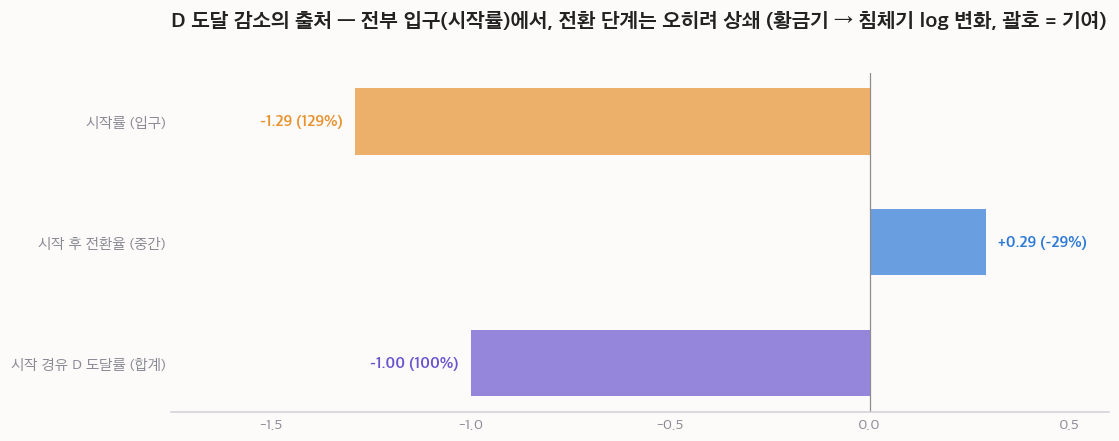

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
parts = [("시작률 (입구)", d_start, vs.ORANGE), ("시작 후 전환율 (중간)", d_conv, vs.BLUE), ("시작 경유 D 도달률 (합계)", total, vs.PURPLE)]
y = np.arange(len(parts))[::-1]
for yi, (name, v, col) in zip(y, parts):
    ax.barh(yi, v, color=col, alpha=0.7, height=0.55)
    ax.annotate(f"{v:+.2f} ({v / total:.0%})", (v, yi), xytext=(-8 if v < 0 else 8, 0), textcoords="offset points",
                ha="right" if v < 0 else "left", va="center", color=col, fontweight="bold", fontsize=10, bbox=vs.LABEL_BOX)
ax.set_yticks(y); ax.set_yticklabels([p[0] for p in parts]); ax.axvline(0, color=vs.GRAY, lw=0.8)
ax.set_xlim(-1.75, 0.6); ax.grid(axis="y", visible=False)
ax.set_title("D 도달 감소의 출처 — 전부 입구(시작률)에서, 전환 단계는 오히려 상쇄 (황금기 → 침체기 log 변화, 괄호 = 기여)", loc="left", fontweight="bold")
fig.savefig(f"{FIG}/03_funnel_decomposition.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

## §4 층화 비교와 구성 표준화

시작 경로(팀 합류 / 노트북) × 시작 시점(당일 / 1~7일 / 8~90일) 6칸으로 나눠 **같은 칸끼리** 비교한다. 그다음 침체기 칸별 전환율에 **황금기 시작자의 칸 구성**을 가중해서, 구성이 같았다면 침체기 전환율이 얼마였을지 계산한다 (직접 표준화).

- 표준화 전환율 = Σ (황금기 칸 비중 × 침체기 칸 전환율)
- 95% CI: 칸 비중은 고정, 칸 전환율의 이항 분산으로 계산 (델타 방법)

In [5]:
cell = st.groupby(["entry", "speed", "period"]).conv.agg(["mean", "size"]).unstack()
share = cell["size"] / cell["size"].sum()
strata = pd.DataFrame({"황금기 전환율": cell["mean"]["Golden"], "침체기 전환율": cell["mean"]["Stagnation"],
                       "황금기 시작자 비중": share["Golden"], "침체기 시작자 비중": share["Stagnation"]})
strata["상대 차이"] = strata["침체기 전환율"] / strata["황금기 전환율"] - 1
strata.style.format({c: "{:.1%}" for c in strata.columns[:4]} | {"상대 차이": "{:+.1%}"})

In [6]:
def standardized(df):
    g, s = df[df.period == "Golden"], df[df.period == "Stagnation"]
    w = g.groupby(["entry", "speed"]).size() / len(g)
    rs = s.groupby(["entry", "speed"]).conv.agg(["mean", "size"])
    est = (w * rs["mean"]).sum(); var = (w ** 2 * rs["mean"] * (1 - rs["mean"]) / rs["size"]).sum()
    rg = g.conv.mean(); vg = rg * (1 - rg) / len(g)
    rel = est / rg - 1; se = np.sqrt(var / rg ** 2 + est ** 2 * vg / rg ** 4)
    lo, hi = rel - 1.96 * se, rel + 1.96 * se
    verdict = lambda m: "기각(동등)" if (lo > -m and hi < m) else ("지지" if hi < -m else "판정 불가")
    return pd.Series({"시작자 (황금기)": len(g), "시작자 (침체기)": len(s), "황금기 전환율": rg, "침체기 단순": s.conv.mean(),
                      "침체기 표준화": est, "표준화 상대 차이": rel, "95% CI": f"[{lo:+.1%}, {hi:+.1%}]",
                      "5% 기준": verdict(0.05), "10% 기준": verdict(0.10)})

FMT = {"시작자 (황금기)": "{:,.0f}", "시작자 (침체기)": "{:,.0f}", "황금기 전환율": "{:.2%}", "침체기 단순": "{:.2%}",
       "침체기 표준화": "{:.2%}", "표준화 상대 차이": "{:+.1%}"}
main = pd.DataFrame([standardized(st).rename("기본"), standardized(st[st.entry == "팀 합류"]).rename("팀 합류 경로만")])
main.style.format(FMT)

,시작자 (황금기),시작자 (침체기),황금기 전환율,침체기 단순,침체기 표준화,표준화 상대 차이,95% CI,5% 기준,10% 기준
기본,"240,893","193,098",23.06%,30.85%,22.65%,-1.8%,"[-2.8%, -0.7%]",기각(동등),기각(동등)
팀 합류 경로만,"224,240","159,400",18.04%,18.02%,17.54%,-2.8%,"[-4.2%, -1.5%]",기각(동등),기각(동등)


[]


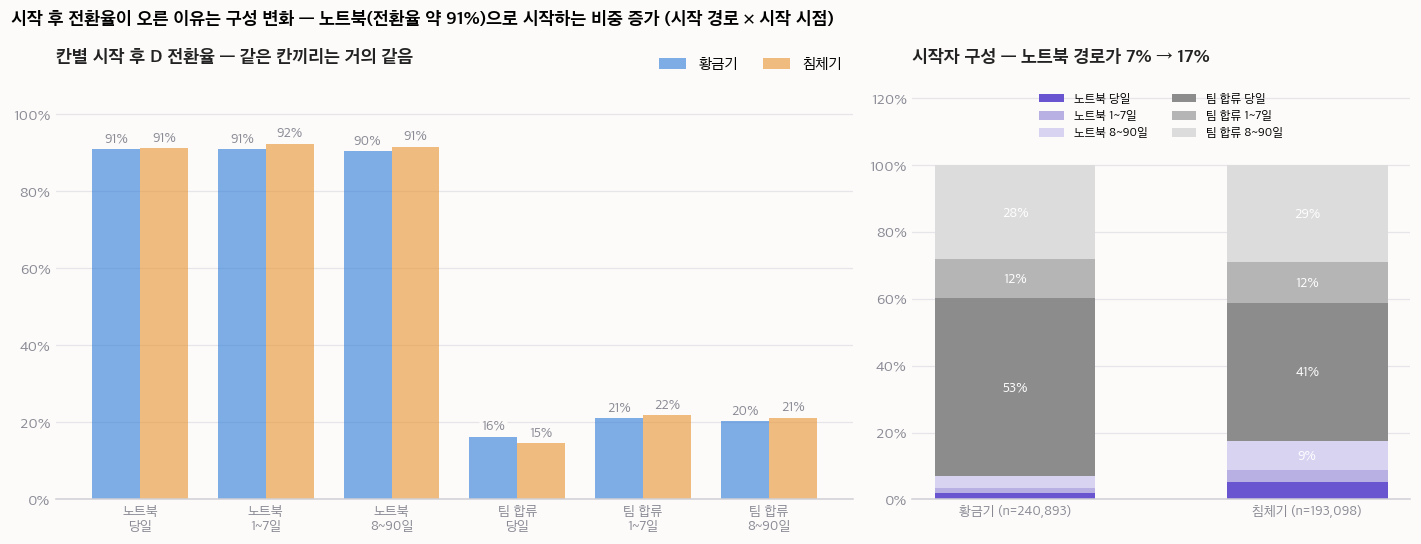

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
lab = [f"{e}\n{s}" for e, s in strata.index]; x = np.arange(len(strata)); w = 0.38
b1 = ax1.bar(x - w / 2, strata["황금기 전환율"], w, color=vs.BLUE, alpha=0.6, label="황금기")
b2 = ax1.bar(x + w / 2, strata["침체기 전환율"], w, color=vs.ORANGE, alpha=0.6, label="침체기")
vs.label_bars(ax1, list(b1) + list(b2), fmt=lambda v: f"{v:.0%}")
ax1.set_xticks(x); ax1.set_xticklabels(lab, fontsize=9); vs.yfmt(ax1, lambda v: f"{v:.0%}")
vs.panel_title(ax1, "칸별 시작 후 D 전환율 — 같은 칸끼리는 거의 같음"); vs.legend_top_right(ax1)
comp_s = strata[["황금기 시작자 비중", "침체기 시작자 비중"]].T
bottom = np.zeros(2); colors = [vs.PURPLE, vs.LAVENDER, "#D9D3F2", vs.GRAY, "#B5B5B5", "#DCDCDC"]
for (idx, col), color in zip(comp_s.items(), colors):
    ax2.bar([0, 1], col.values, bottom=bottom, color=color, width=0.55, label=f"{idx[0]} {idx[1]}")
    for i in range(2):
        if col.values[i] > 0.06:
            ax2.text(i, bottom[i] + col.values[i] / 2, f"{col.values[i]:.0%}", ha="center", va="center", color="white", fontsize=9)
    bottom += col.values
ax2.set_xticks([0, 1]); ax2.set_xticklabels([vs.n_label("황금기", int(cell['size']['Golden'].sum())), vs.n_label("침체기", int(cell['size']['Stagnation'].sum()))], fontsize=9)
vs.yfmt(ax2, lambda v: f"{v:.0%}"); ax2.set_ylim(0, 1.25)
vs.panel_title(ax2, "시작자 구성 — 노트북 경로가 7% → 17%")
ax2.legend(ncol=2, fontsize=8, frameon=False, loc="upper center")
fig.suptitle("시작 후 전환율이 오른 이유는 구성 변화 — 노트북(전환율 약 91%)으로 시작하는 비중 증가 (시작 경로 × 시작 시점)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/03_strata.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

- 같은 칸끼리는 전환율이 거의 같다. 노트북 경로는 두 시기 모두 약 91%, 팀 합류 경로는 15 ~ 22%.
- 구성을 황금기에 맞추면 침체기 전환율은 황금기와 동등 범위 안이다 → **가설2 기각**.
- 노트북 경로의 91%는 "노트북 작성 → 공개(= D)"가 정의상 가까워서 나오는 숫자다. 실질적인 전환력으로 해석하지 않는다.

## §5 견고성

In [8]:
rows = [standardized(st).rename("기본"),
        standardized(st[~st.same_day]).rename("같은 날 D 제외 (하루 이상 걸린 전환만)")]
for lines, versions in [(50, 4), (30, 2), (100, 8)]:
    cgrp = st[(st.first_team <= 90) | (st.max_lines_90d >= lines) | (st.max_versions_90d >= versions)]
    rows.append(standardized(cgrp).rename(f"시도자(C그룹): 팀 합류 OR {lines}줄↑ OR 수정 {versions}회↑"))
robust = pd.DataFrame(rows)
robust.style.format(FMT)

,시작자 (황금기),시작자 (침체기),황금기 전환율,침체기 단순,침체기 표준화,표준화 상대 차이,95% CI,5% 기준,10% 기준
기본,"240,893","193,098",23.06%,30.85%,22.65%,-1.8%,"[-2.8%, -0.7%]",기각(동등),기각(동등)
같은 날 D 제외 (하루 이상 걸린 전환만),"217,911","165,308",14.95%,19.22%,14.03%,-6.1%,"[-7.5%, -4.7%]",판정 불가,기각(동등)
시도자(C그룹): 팀 합류 OR 50줄↑ OR 수정 4회↑,"238,864","189,702",22.67%,30.32%,22.28%,-1.7%,"[-2.8%, -0.6%]",기각(동등),기각(동등)
시도자(C그룹): 팀 합류 OR 30줄↑ OR 수정 2회↑,"240,241","192,349",22.98%,30.87%,22.57%,-1.8%,"[-2.8%, -0.7%]",기각(동등),기각(동등)
시도자(C그룹): 팀 합류 OR 100줄↑ OR 수정 8회↑,"236,096","184,210",21.87%,28.50%,21.47%,-1.8%,"[-2.9%, -0.7%]",기각(동등),기각(동등)


- **같은 날 D를 빼면 약한 하락이 보인다** (−6.2%, CI −7.6 ~ −4.8%). 그날 바로 D까지 간 사람을 빼면, 하루 이상 걸려 전환하는 사람에게서는 침체기가 조금 낮다. 5% 기준으로는 CI가 기준선에 걸려 판정 불가, 10% 기준으로는 동등. 후속 확인 거리로 남긴다.
- **시도자(C그룹) 문턱은 결과를 거의 바꾸지 않는다.** 다만 팀 합류만으로도 시도자가 되므로 문턱을 바꿔도 대상자의 98% 이상이 그대로다. 강한 견고성 확인은 아니다.

## §6 분모의 함정

같은 D 전환을 **어떤 분모로 나누느냐**에 따라 방향이 반대로 나온다.

[]


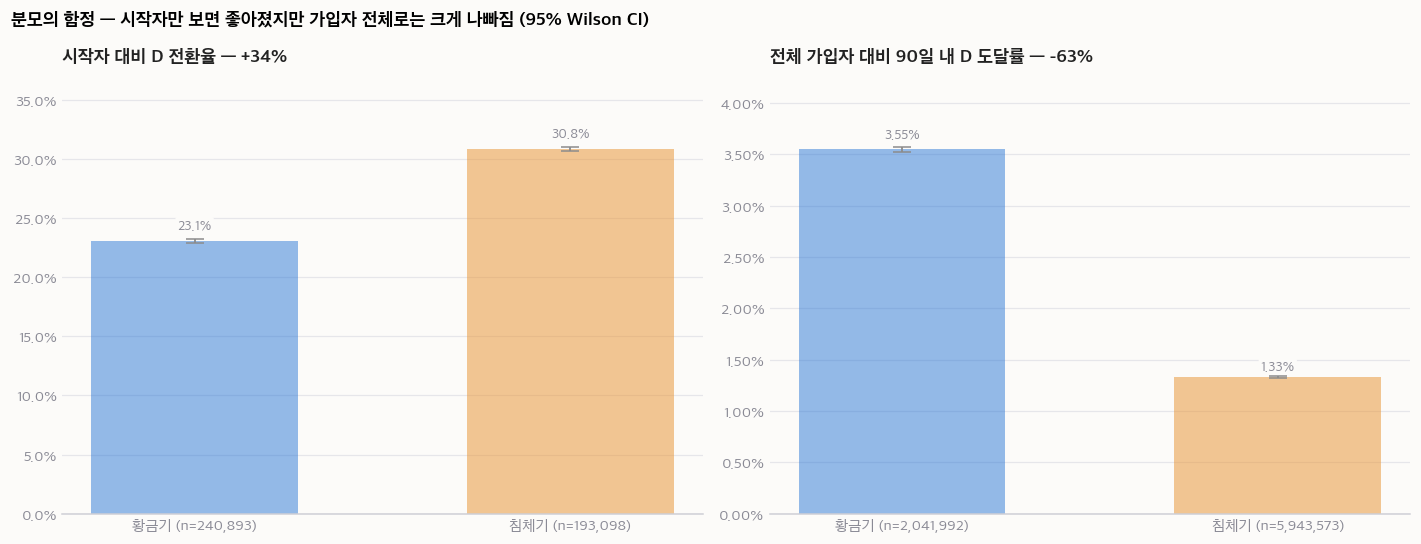

In [9]:
conv_x = {p: int(st.loc[st.period == p, "conv"].sum()) for p in PERIODS}; conv_n = {p: int((st.period == p).sum()) for p in PERIODS}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
panels = [("시작자 대비 D 전환율 — +34%", conv_x, conv_n, lambda v: f"{v:.1%}"),
          ("전체 가입자 대비 90일 내 D 도달률 — -63%", {p: int(d_reach[p]) for p in PERIODS}, N, lambda v: f"{v:.2%}")]
for ax, (title, x_, n_, f) in zip(axes, panels):
    vals, err = [], [[], []]
    for p in PERIODS:
        v = x_[p] / n_[p]; lo, hi = proportion_confint(x_[p], n_[p], method="wilson")
        vals.append(v); err[0].append(v - lo); err[1].append(hi - v)
    bars = ax.bar([vs.n_label(KO[p], n_[p]) for p in PERIODS], vals, yerr=err, capsize=6, color=[vs.BLUE, vs.ORANGE], alpha=0.5, width=0.55,
                  error_kw=dict(ecolor=vs.GRAY, lw=1.2))
    vs.label_bars(ax, bars, fmt=f); vs.yfmt(ax, f); vs.panel_title(ax, title)
fig.suptitle("분모의 함정 — 시작자만 보면 좋아졌지만 가입자 전체로는 크게 나빠짐 (95% Wilson CI)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/03_denominator_trap.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

## 결론

1. **문제는 중간 단계가 아니라 입구다.** 시작한 사람은 황금기와 같은 비율로 D까지 간다. D 도달 감소는 시작률 하락(가설1)으로 전부 설명된다.
2. **"전환율이 올랐다"는 구성 착시다.** 노트북으로 시작하는 사람의 비중이 늘었을 뿐, 같은 경로끼리는 그대로다. 시작자만 보는 지표로 판단하면 "시스템이 좋아졌다"는 잘못된 결론에 이른다(분모의 함정).
3. **약한 신호 하나**: 하루 이상 걸리는 전환에서는 침체기가 6% 낮다. 활성화 개선을 검토한다면 "참여 후 첫 며칠"이 후보 지점이다.

**액션**: 개선 노력의 우선순위는 활성화 단계보다 **가입 직후 첫 참여**(02 노트북: 격차의 57%가 가입 당일)에 둔다.

**한계**: 표준화는 관측되는 차이(경로·시점)만 통제한다. 의지·목적처럼 관측되지 않는 차이는 남는다. D 정의상 노트북 경로는 전환이 쉬워서 경로 간 전환율 비교는 해석에 주의한다.